# Benchmark: labour-force participation in Mroz's PSID sample

Eleven classifiers on Mroz's 753 married women from the 1975 PSID {cite:p}`mroz1987sensitivity`, scored on held-out log loss over 8 shared 80/20 splits. Every method is run twice: with the wage variable `lwg` as the data set ships it, and without it. The second run exists because `lwg` is not a clean covariate, and the comparison changes completely when it is removed.

This page reads a recorded artifact and refits nothing.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how eleven classifiers score on held-out Mroz rows, with and without the imputed wage |
| **Observed response** | `lfp`, whether the woman was in the labour force in 1975 (binary) |
| **Estimand** | mean held-out log loss (Bernoulli negative log-likelihood) of the predicted probability; AUC and Brier score alongside |
| **Units** | nats per held-out woman; AUC and Brier are unitless |
| **Sampling unit** | one married woman in the 1975 PSID sample |
| **Dependence** | treated as independent across women |
| **Split / resampling unit** | the woman; the same 8 random 80/20 splits for every method and both variants |
| **Tuning** | `tune_mstop` (5-fold CV) for mboostrs; `gridsearch` for pyGAM; default L2 for scikit-learn's logistic regression; 400 rounds at learning rate 0.05 for the trees, plus a LightGBM arm with rounds chosen by 5-fold CV early stopping |
| **Uncertainty** | across-split standard errors and paired per-split differences against the logit |
| **Claim type** | predictive comparison under the stated protocol; the with-`lwg` variant measures how well a method exploits an imputation artefact, not participation |
:::

In [1]:
from IPython.display import display
import altair as alt
import numpy as np
import polars as pl

from public_tasks import (
    failures, lines, load, memory, paired, protocol, summary, table, warnings_by_method,
)

bench, runs = load("binary")
display(table(
    protocol(bench), stub="item", stubhead="Item",
    title="What was run", subtitle="Pinned source, shared splits, one thread per library",
    notes=["Source: bench_public_binary.json, written by benches/bench_public_tasks.py."],
))

GT(_tbl_data=shape: (11, 2)
┌───────────────────────┬─────────────────────────────────┐
│ item                  ┆ value                           │
│ ---                   ┆ ---                             │
│ str                   ┆ str                             │
╞═══════════════════════╪═════════════════════════════════╡
│ source                ┆ https://raw.githubusercontent.… │
│ source sha256         ┆ e7d618f518d247ce…               │
│ train fraction        ┆ 0.8                             │
│ seeds (random splits) ┆ 8                               │
│ trees (fixed setting) ┆ 400 rounds, learning rate 0.05  │
│ …                     ┆ …                               │
│ versions              ┆ mboostrs 0.1.3, polars 2.0.0, … │
│ commit                ┆ 836c450c8c + uncommitted runne… │
│ runner sha256         ┆ ccd6242f4a5b001a…               │
│ measured at (UTC)     ┆ 2026-10-08T22:18:26+00:00       │
│ machine               ┆ Intel(R) Xeon(R) Processor, 8 … │
└───────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10b710320>, _boxhead=Boxhead([ColInfo(var='item', type=<ColInfoTypeEnum.stub: 2>, column_label='item', column_align='left', column_width=None), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='value', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b0f6300>, _spanners=Spanners([]), _heading=Heading(title='What was run', subtitle='Pinned source, shared splits, one thread per library', preheader=None), _stubhead='Item', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10aed9af0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10a205100>, _source_notes=['Source: bench_public_binary.json, written by benches/bench_public_tasks.py.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10950fa70>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x109435ca0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_

(why-lwg-needs-a-second-run)=
## Imputed wage covariate: `lwg`

`lwg` is the log of the woman's hourly wage. Wages are observed only for women who worked; for the 325 non-participants the data set carries an imputed value. The two groups look different in a way that has nothing to do with participation: the observed wages spread from -2.05 to 3.22 (SD 0.72), the imputed ones sit in a narrow band from -0.01 to 1.76 (SD 0.29). A model that can bend in `lwg` can learn "a wage outside the imputation band means she worked" — which is reading the imputation rule, not explaining participation.

In [2]:
display(table(
    pl.DataFrame(bench["evidence"]["lwg_by_lfp"]).with_columns(
        pl.when(pl.col("lfp") == 1).then(pl.lit("participants (observed wage)"))
        .otherwise(pl.lit("non-participants (imputed wage)")).alias("group")
    ).select("group", "rows", "mean", "sd", "min", "max"),
    stub="group", stubhead="Group",
    title="The distribution of lwg by participation",
    subtitle="All 753 rows; lwg is observed for participants and imputed for the rest",
    labels={"rows": "rows", "mean": "mean", "sd": "SD", "min": "min", "max": "max"},
    decimals=2,
    notes=["Source: the pinned Rdatasets copy of carData::Mroz, summarised by the runner."],
))

GT(_tbl_data=shape: (2, 6)
┌─────────────────────────────────┬──────┬──────────┬──────────┬───────────┬───────────┐
│ group                           ┆ rows ┆ mean     ┆ sd       ┆ min       ┆ max       │
│ ---                             ┆ ---  ┆ ---      ┆ ---      ┆ ---       ┆ ---       │
│ str                             ┆ i64  ┆ f64      ┆ f64      ┆ f64       ┆ f64       │
╞═════════════════════════════════╪══════╪══════════╪══════════╪═══════════╪═══════════╡
│ non-participants (imputed wage… ┆ 325  ┆ 0.974564 ┆ 0.292366 ┆ -0.005835 ┆ 1.7576321 │
│ participants (observed wage)    ┆ 428  ┆ 1.190173 ┆ 0.723194 ┆ -2.054124 ┆ 3.2188759 │
└─────────────────────────────────┴──────┴──────────┴──────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x109d9f980>, _boxhead=Boxhead([ColInfo(var='group', type=<ColInfoTypeEnum.stub: 2>, column_label='group', column_align='left', column_width=None), ColInfo(var='rows', type=<ColInfoTypeEnum.default: 1>, column_label='rows', column_align='right', column_width=None), ColInfo(var='mean', type=<ColInfoTypeEnum.default: 1>, column_label='mean', column_align='right', column_width=None), ColInfo(var='sd', type=<ColInfoTypeEnum.default: 1>, column_label='SD', column_align='right', column_width=None), ColInfo(var='min', type=<ColInfoTypeEnum.default: 1>, column_label='min', column_align='right', column_width=None), ColInfo(var='max', type=<ColInfoTypeEnum.default: 1>, column_label='max', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10ae3f9e0>, _spanners=Spanners([]), _heading=Heading(title='The distribution of lwg by participation', subtitle='All 753 rows; lwg is observed for participants and imputed for the rest', preheader=None), _stubhead='Group', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b12bb00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b156840>, _source_notes=['Source: the pinned Rdatasets copy of carData::Mroz, summarised by the runner.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10b7f66f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10b7322d0>, <great_tables._gt_data.FormatInfo object at 0x109fa2a50>, <great_tables._gt_data.FormatInfo object at 0x10b12a570>, <great_tables._gt_data.FormatInfo object at 0x10b7f68d0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10b7f4620>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=Tr

## Held-out scores

In [3]:
ORDER_KEY = pl.col("method").replace_strict({'LightGBM (CV rounds)': 0, 'mboostrs autospec': 1, 'mboostrs suggest_terms': 2, 'pyGAM LogisticGAM': 3, 'mboostrs Binomial': 4, 'CatBoost': 5, 'XGBoost': 6, 'sklearn LogisticRegression': 7, 'statsmodels Logit': 8, 'LightGBM': 9, 'sklearn HGB': 10}, default=99)
scores = (summary(runs, ["log_loss", "auc", "brier"], by=("variant", "method"))
          .with_columns(ORDER_KEY.alias("o")).sort("variant", "o").drop("o"))
display(table(
    scores.select("variant", "method", "log_loss", "log_loss_se", "auc", "brier", "failed", "seconds"),
    stub="method", stubhead="Method", group="variant",
    title="Held-out scores on Mroz",
    subtitle="Mean over 8 shared 80/20 splits of 753 women, with and without lwg",
    labels={"log_loss": "log loss ↓", "log_loss_se": "± SE", "auc": "AUC ↑", "brier": "Brier ↓",
            "failed": "failed", "seconds": "s"},
    better={"log_loss": "min", "auc": "max", "brier": "min"},
    formats={"log_loss_se": 3, "seconds": 2}, decimals=3,
    notes=["Bold marks the best value within each variant. s is the median seconds for the whole "
           "workflow (tuning, fit, predict). failed counts seeds that raised; their scores are "
           "excluded from that row's means (see Failed fits)."],
))

GT(_tbl_data=shape: (22, 8)
┌─────────────┬─────────────────┬──────────┬─────────────┬──────────┬──────────┬────────┬──────────┐
│ variant     ┆ method          ┆ log_loss ┆ log_loss_se ┆ auc      ┆ brier    ┆ failed ┆ seconds  │
│ ---         ┆ ---             ┆ ---      ┆ ---         ┆ ---      ┆ ---      ┆ ---    ┆ ---      │
│ str         ┆ str             ┆ f64      ┆ f64         ┆ f64      ┆ f64      ┆ u32    ┆ f64      │
╞═════════════╪═════════════════╪══════════╪═════════════╪══════════╪══════════╪════════╪══════════╡
│ with lwg    ┆ LightGBM (CV    ┆ 0.496845 ┆ 0.00632     ┆ 0.829331 ┆ 0.166925 ┆ 0      ┆ 0.09769  │
│             ┆ rounds)         ┆          ┆             ┆          ┆          ┆        ┆          │
│ with lwg    ┆ mboostrs        ┆ 0.501958 ┆ 0.009596    ┆ 0.827263 ┆ 0.169198 ┆ 2      ┆ 2.146659 │
│             ┆ autospec        ┆          ┆             ┆          ┆          ┆        ┆          │
│ with lwg    ┆ mboostrs        ┆ 0.502813 ┆ 0.006011    ┆ 0.835226 ┆ 0.169928 ┆ 4      ┆ 0.059676 │
│             ┆ suggest_terms   ┆          ┆             ┆          ┆          ┆        ┆          │
│ with lwg    ┆ pyGAM           ┆ 0.50584  ┆ 0.008803    ┆ 0.825392 ┆ 0.17113  ┆ 0      ┆ 0.327079 │
│             ┆ LogisticGAM     ┆          ┆             ┆          ┆          ┆        ┆          │
│ with lwg    ┆ mboostrs        ┆ 0.506533 ┆ 0.00812     ┆ 0.826523 ┆ 0.171302 ┆ 0      ┆ 0.065812 │
│             ┆ Binomial        ┆          ┆             ┆          ┆          ┆        ┆          │
│ …           ┆ …               ┆ …        ┆ …           ┆ …        ┆ …        ┆ …      ┆ …        │
│ without lwg ┆ XGBoost         ┆ 0.764471 ┆ 0.014657    ┆ 0.6204   ┆ 0.265091 ┆ 0      ┆ 0.05978  │
│ without lwg ┆ sklearn Logisti ┆ 0.623584 ┆ 0.006114    ┆ 0.70596  ┆ 0.21603  ┆ 0      ┆ 0.004415 │
│             ┆ cRegression     ┆          ┆             ┆          ┆          ┆        ┆          │
│ without lwg ┆ statsmodels     ┆ 0.623769 ┆ 0.006236    ┆ 0.705828 ┆ 0.216041 ┆ 0      ┆ 0.002169 │
│             ┆ Logit           ┆          ┆             ┆          ┆          ┆        ┆          │
│ without lwg ┆ LightGBM        ┆ 0.843985 ┆ 0.021008    ┆ 0.623594 ┆ 0.279225 ┆ 0      ┆ 0.058535 │
│ without lwg ┆ sklearn HGB     ┆ 0.880977 ┆ 0.025616    ┆ 0.615834 ┆ 0.288539 ┆ 0      ┆ 0.307115 │
└─────────────┴─────────────────┴──────────┴─────────────┴──────────┴──────────┴────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10b797680>, _boxhead=Boxhead([ColInfo(var='variant', type=<ColInfoTypeEnum.row_group: 3>, column_label='variant', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='log_loss', type=<ColInfoTypeEnum.default: 1>, column_label='log loss ↓', column_align='right', column_width=None), ColInfo(var='log_loss_se', type=<ColInfoTypeEnum.default: 1>, column_label='± SE', column_align='right', column_width=None), ColInfo(var='auc', type=<ColInfoTypeEnum.default: 1>, column_label='AUC ↑', column_align='right', column_width=None), ColInfo(var='brier', type=<ColInfoTypeEnum.default: 1>, column_label='Brier ↓', column_align='right', column_width=None), ColInfo(var='failed', type=<ColInfoTypeEnum.default: 1>, column_label='failed', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b794f20>, _spanners=Spanners([]), _heading=Heading(title='Held-out scores on Mroz', subtitle='Mean over 8 shared 80/20 splits of 753 women, with and without lwg', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x109fa20f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b7f7350>, _source_notes=["Bold marks the best value within each variant. s is the median seconds for th

## Score comparisons

**With `lwg`, flexible models exploit its imputation pattern.** mboostrs, pyGAM, CatBoost and the CV-rounds LightGBM all land between 0.497 and 0.507 log loss, about 0.11 nats ahead of the logit (0.617), and their AUC rises to about 0.83 against 0.72. The logit has one slope for `lwg` and cannot represent "inside the band versus outside it"; a smooth or a tree can. The score difference is consistent with the imputation artefact and does not establish nonlinearity in participation.

**Without `lwg`, the logit is best and the gap closes.** The logit scores 0.624. mboostrs is +0.006 (paired SE 0.005) and pyGAM +0.007 (SE 0.006) behind it — differences that are small relative to their paired standard errors. With 602 training rows, smooth terms for young children, age, the wife's college and other income do not measurably improve on linear logit terms in these splits. The flexible models' entire advantage in the first run came from `lwg`.

**Fixed tree budgets have higher loss without `lwg`.** Without `lwg`, even the CV-rounds LightGBM is +0.029 (SE 0.007) behind the logit, and the fixed 400-round trees are much further back. Early stopping chose 16–34 rounds without `lwg` and 46–57 with it: on 602 training rows, where a linear logit is already the best model here, there is little for a tree to find, and a fixed budget fits noise.

`tune_mstop` reflects the same thing for mboostrs: the median chosen step count is 224 with `lwg` and 90 without, which fits the reading that there is less signal to chase once the artefact is gone.

In [4]:
paired_rows = pl.concat([
    paired(runs.filter(pl.col("variant") == variant), "log_loss", "statsmodels Logit")
    .with_columns(pl.lit(variant).alias("variant"))
    for variant in ("with lwg", "without lwg")
])
display(table(
    paired_rows.with_columns(ORDER_KEY.alias("o")).sort("variant", "o").drop("o")
    .select("variant", "method", "pairs", "difference", "difference_se"),
    stub="method", stubhead="Method", group="variant",
    title="Paired log-loss difference from the logit",
    subtitle="Mean over splits of (method − statsmodels Logit); negative is better",
    labels={"pairs": "splits", "difference": "Δ log loss", "difference_se": "± SE"},
    better={"difference": "min"}, decimals=3,
    notes=["Pairs are the splits on which both finished; SE is the standard deviation of the "
           "per-split difference over the square root of the pairs."],
))

GT(_tbl_data=shape: (20, 5)
┌─────────────┬────────────────────────────┬───────┬────────────┬───────────────┐
│ variant     ┆ method                     ┆ pairs ┆ difference ┆ difference_se │
│ ---         ┆ ---                        ┆ ---   ┆ ---        ┆ ---           │
│ str         ┆ str                        ┆ u32   ┆ f64        ┆ f64           │
╞═════════════╪════════════════════════════╪═══════╪════════════╪═══════════════╡
│ with lwg    ┆ LightGBM (CV rounds)       ┆ 8     ┆ -0.119977  ┆ 0.009081      │
│ with lwg    ┆ mboostrs autospec          ┆ 6     ┆ -0.110873  ┆ 0.006836      │
│ with lwg    ┆ mboostrs suggest_terms     ┆ 4     ┆ -0.112474  ┆ 0.00899       │
│ with lwg    ┆ pyGAM LogisticGAM          ┆ 8     ┆ -0.110982  ┆ 0.005852      │
│ with lwg    ┆ mboostrs Binomial          ┆ 8     ┆ -0.110289  ┆ 0.004873      │
│ …           ┆ …                          ┆ …     ┆ …          ┆ …             │
│ without lwg ┆ CatBoost                   ┆ 8     ┆ 0.068745   ┆ 0.014503      │
│ without lwg ┆ XGBoost                    ┆ 8     ┆ 0.140702   ┆ 0.013536      │
│ without lwg ┆ sklearn LogisticRegression ┆ 8     ┆ -0.000185  ┆ 0.000134      │
│ without lwg ┆ LightGBM                   ┆ 8     ┆ 0.220216   ┆ 0.020585      │
│ without lwg ┆ sklearn HGB                ┆ 8     ┆ 0.257208   ┆ 0.024933      │
└─────────────┴────────────────────────────┴───────┴────────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x10b797680>, _boxhead=Boxhead([ColInfo(var='variant', type=<ColInfoTypeEnum.row_group: 3>, column_label='variant', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='pairs', type=<ColInfoTypeEnum.default: 1>, column_label='splits', column_align='right', column_width=None), ColInfo(var='difference', type=<ColInfoTypeEnum.default: 1>, column_label='Δ log loss', column_align='right', column_width=None), ColInfo(var='difference_se', type=<ColInfoTypeEnum.default: 1>, column_label='± SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10adac890>, _spanners=Spanners([]), _heading=Heading(title='Paired log-loss difference from the logit', subtitle='Mean over splits of (method − statsmodels Logit); negative is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b84ce00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b84d8e0>, _source_notes=['Pairs are the splits on which both finished; SE is the standard deviation of the per-split difference over the square root of the pairs.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B84ECF0>, mask=None), grpname=None, colname='pairs', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B84ECF0>, mask=None), grpname=None, colname='pairs', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B84ECF0>, mask=None), grpname=None, colname='pairs', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B84ECF0>, mask=None), grpname=None, colname='pairs', rownum=11, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B84ECF0>, mask=None), grpname=None, colname='pairs', rownum=12, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B84ECF0>, mask=None), grpname=None, colname='pairs', rownum=14, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), Sty

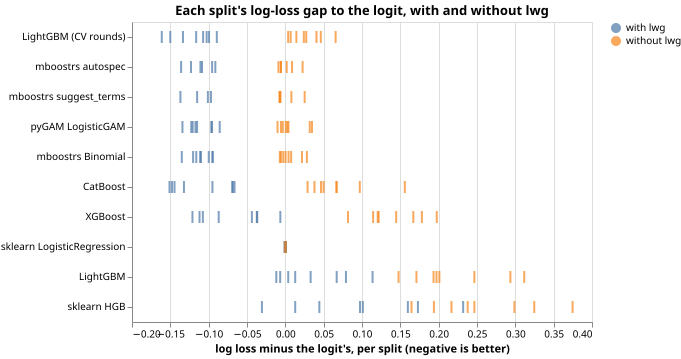

In [5]:
ORDER = ['LightGBM (CV rounds)', 'mboostrs autospec', 'mboostrs suggest_terms', 'pyGAM LogisticGAM', 'mboostrs Binomial', 'CatBoost', 'XGBoost', 'sklearn LogisticRegression', 'statsmodels Logit', 'LightGBM', 'sklearn HGB']
per_split = (
    runs.filter(pl.col("status") == "success")
    .join(runs.filter(pl.col("method") == "statsmodels Logit")
          .select("seed", "variant", pl.col("log_loss").alias("logit")), on=["seed", "variant"])
    .with_columns((pl.col("log_loss") - pl.col("logit")).alias("difference"))
    .filter(pl.col("method") != "statsmodels Logit")
)
alt.Chart(per_split).mark_tick(thickness=2, size=12).encode(
    x=alt.X("difference:Q", title="log loss minus the logit's, per split (negative is better)"),
    y=alt.Y("method:N", sort=ORDER, title=None),
    color=alt.Color("variant:N", title=None),
).properties(width=460, height=300,
             title="Each split's log-loss gap to the logit, with and without lwg")

## Failures and the default specification

`suggest_terms` failed on 4 of 8 splits with `lwg` and 3 without, and `autospec` on 2 and 2. Almost all are the same cause: `suggest_terms` types the small counts `k5` and `k618` as `brandom` group terms, and a held-out woman whose count is too rare to land in every training split makes `predict` refuse the unseen level. The refused levels here are three young children and seven or eight older ones. One `autospec` failure is a separate parse error on a transformed predictor. The hand-written mboostrs formula uses `bols` for the counts and never fails. When the defaults finish, they score about as well as the hand-written model. Their failures reduce reliability without materially changing these completed-run scores.

In [6]:
ORDER_KEY = pl.col("method").replace_strict({'LightGBM (CV rounds)': 0, 'mboostrs autospec': 1, 'mboostrs suggest_terms': 2, 'pyGAM LogisticGAM': 3, 'mboostrs Binomial': 4, 'CatBoost': 5, 'XGBoost': 6, 'sklearn LogisticRegression': 7, 'statsmodels Logit': 8, 'LightGBM': 9, 'sklearn HGB': 10}, default=99)
fails = failures(runs)
display(table(
    fails if fails.height else pl.DataFrame({"method": ["(none)"], "seed": [None], "error": [""]}),
    stub="method", stubhead="Method",
    title="Failed fits", subtitle="Each unsuccessful (method, seed) with the first line of its error",
    notes=["A failed seed is excluded from that method's means and counted in its failed column."],
))

GT(_tbl_data=shape: (11, 4)
┌────────────────────────┬─────────────┬──────┬─────────────────────────────────┐
│ method                 ┆ variant     ┆ seed ┆ error                           │
│ ---                    ┆ ---         ┆ ---  ┆ ---                             │
│ str                    ┆ str         ┆ i64  ┆ str                             │
╞════════════════════════╪═════════════╪══════╪═════════════════════════════════╡
│ mboostrs suggest_terms ┆ with lwg    ┆ 0    ┆ MboostrsValueError: unknown Br… │
│ mboostrs suggest_terms ┆ without lwg ┆ 0    ┆ MboostrsValueError: unknown Br… │
│ mboostrs suggest_terms ┆ with lwg    ┆ 1    ┆ MboostrsValueError: unknown Br… │
│ mboostrs autospec      ┆ with lwg    ┆ 1    ┆ MboostrsValueError: unknown Br… │
│ mboostrs suggest_terms ┆ without lwg ┆ 1    ┆ MboostrsValueError: unknown Br… │
│ …                      ┆ …           ┆ …    ┆ …                               │
│ mboostrs suggest_terms ┆ with lwg    ┆ 3    ┆ MboostrsValueError: unknown Br… │
│ mboostrs autospec      ┆ with lwg    ┆ 6    ┆ ValueError: cannot parse formu… │
│ mboostrs suggest_terms ┆ with lwg    ┆ 7    ┆ MboostrsValueError: unknown Br… │
│ mboostrs suggest_terms ┆ without lwg ┆ 7    ┆ MboostrsValueError: unknown Br… │
│ mboostrs autospec      ┆ without lwg ┆ 7    ┆ MboostrsValueError: unknown Br… │
└────────────────────────┴─────────────┴──────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10b797680>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='variant', type=<ColInfoTypeEnum.default: 1>, column_label='variant', column_align='left', column_width=None), ColInfo(var='seed', type=<ColInfoTypeEnum.default: 1>, column_label='seed', column_align='right', column_width=None), ColInfo(var='error', type=<ColInfoTypeEnum.default: 1>, column_label='error', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b6f12b0>, _spanners=Spanners([]), _heading=Heading(title='Failed fits', subtitle='Each unsuccessful (method, seed) with the first line of its error', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10ac3efc0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b8af8f0>, _source_notes=["A failed seed is excluded from that method's means and counted in its failed column."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AF2F0>, mask=None), grpname=None, colname='variant', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AF2F0>, mask=None), grpname=None, colname='variant', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AF2F0>, mask=None), grpname=None, colname='variant', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AF2F0>, mask=None), grpname=None, colname='variant', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AF2F0>, mask=None), grpname=None, colname='variant', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AF2F0>, mask=None), grpname=None, colname='variant', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AF2F0>, mask=None), grpname=None, colname='variant', rownum=6, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInf

In [7]:
display(table(
    memory(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Peak memory of one fit",
    subtitle="Fresh process, seed 0: VmHWM after the fit minus VmRSS before it",
    labels={"seconds": "s", "peak_rss_growth_mb": "Δ RSS MB", "status": "status"},
    better={"peak_rss_growth_mb": "min"}, formats={"seconds": 2, "peak_rss_growth_mb": 1},
    notes=["The high-water mark is reset after imports and data loading, so the figure is the "
           "fit's own growth. One probe per method; descriptive, not averaged."],
))

GT(_tbl_data=shape: (11, 4)
┌────────────────────────────┬──────────┬────────────────────┬─────────┐
│ method                     ┆ seconds  ┆ peak_rss_growth_mb ┆ status  │
│ ---                        ┆ ---      ┆ ---                ┆ ---     │
│ str                        ┆ f64      ┆ f64                ┆ str     │
╞════════════════════════════╪══════════╪════════════════════╪═════════╡
│ LightGBM (CV rounds)       ┆ 0.108113 ┆ 7.996094           ┆ success │
│ mboostrs autospec          ┆ 2.128566 ┆ 13.8125            ┆ success │
│ mboostrs suggest_terms     ┆ null     ┆ null               ┆ error   │
│ pyGAM LogisticGAM          ┆ 0.420568 ┆ 9.847656           ┆ success │
│ mboostrs Binomial          ┆ 0.060755 ┆ 9.3671875          ┆ success │
│ …                          ┆ …        ┆ …                  ┆ …       │
│ XGBoost                    ┆ 0.091957 ┆ 10.023438          ┆ success │
│ sklearn LogisticRegression ┆ 0.02054  ┆ 2.277344           ┆ success │
│ statsmodels Logit          ┆ 0.003118 ┆ 2.449219           ┆ success │
│ LightGBM                   ┆ 0.08371  ┆ 8.6015625          ┆ success │
│ sklearn HGB                ┆ 0.293465 ┆ 3.515625           ┆ success │
└────────────────────────────┴──────────┴────────────────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x10b731eb0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None), ColInfo(var='peak_rss_growth_mb', type=<ColInfoTypeEnum.default: 1>, column_label='Δ RSS MB', column_align='right', column_width=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10aed9af0>, _spanners=Spanners([]), _heading=Heading(title='Peak memory of one fit', subtitle='Fresh process, seed 0: VmHWM after the fit minus VmRSS before it', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x109fa20f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x109fa27b0>, _source_notes=["The high-water mark is reset after imports and data loading, so the figure is the fit's own growth. One probe per method; descriptive, not averaged."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AC350>, mask=None), grpname=None, colname='seconds', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AC350>, mask=None), grpname=None, colname='seconds', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AC350>, mask=None), grpname=None, colname='seconds', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AC350>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AC350>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AC350>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AC350>, mask=None), grpname=None, colname='status', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, 

In [8]:
display(table(
    warnings_by_method(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Warnings raised during the fits",
    subtitle="Distinct warning texts across all seeds, with one example",
    labels={"distinct_warnings": "distinct", "example": "example"},
    notes=["Methods that raised none are omitted."],
))
display(table(
    lines(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Lines of code per method",
    subtitle="Statements in each method's function in benches/bench_public_tasks.py",
    labels={"lines": "lines"},
    notes=["Docstrings, comments and blank lines are not counted. Shared helpers are not "
           "counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds "
           "row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal."],
))

GT(_tbl_data=shape: (4, 3)
┌────────────────────────┬───────────────────┬─────────────────────────────────┐
│ method                 ┆ distinct_warnings ┆ example                         │
│ ---                    ┆ ---               ┆ ---                             │
│ str                    ┆ i64               ┆ str                             │
╞════════════════════════╪═══════════════════╪═════════════════════════════════╡
│ mboostrs autospec      ┆ 14                ┆ ExtrapolationWarning: 1 learne… │
│ mboostrs suggest_terms ┆ 3                 ┆ ExtrapolationWarning: 1 learne… │
│ pyGAM LogisticGAM      ┆ 7                 ┆ DeprecationWarning: Bitwise in… │
│ mboostrs Binomial      ┆ 4                 ┆ ExtrapolationWarning: 1 learne… │
└────────────────────────┴───────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10b797680>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='distinct_warnings', type=<ColInfoTypeEnum.default: 1>, column_label='distinct', column_align='right', column_width=None), ColInfo(var='example', type=<ColInfoTypeEnum.default: 1>, column_label='example', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b84c6e0>, _spanners=Spanners([]), _heading=Heading(title='Warnings raised during the fits', subtitle='Distinct warning texts across all seeds, with one example', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b8ad340>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b8ad400>, _source_notes=['Methods that raised none are omitted.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8ADC10>, mask=None), grpname=None, colname='distinct_warnings', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8ADC10>, mask=None), grpname=None, colname='distinct_warnings', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8ADC10>, mask=None), grpname=None, colname='distinct_warnings', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8ADC10>, mask=None), grpname=None, colname='example', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8ADC10>, mask=None), grpname=None, colname='example', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8ADC10>, mask=None), grpname=None, colname='example', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10b8af0e0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10b8ad9d0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=F

GT(_tbl_data=shape: (11, 2)
┌────────────────────────────┬───────┐
│ method                     ┆ lines │
│ ---                        ┆ ---   │
│ str                        ┆ i64   │
╞════════════════════════════╪═══════╡
│ LightGBM (CV rounds)       ┆ 2     │
│ mboostrs autospec          ┆ 4     │
│ mboostrs suggest_terms     ┆ 6     │
│ pyGAM LogisticGAM          ┆ 8     │
│ mboostrs Binomial          ┆ 5     │
│ …                          ┆ …     │
│ XGBoost                    ┆ 2     │
│ sklearn LogisticRegression ┆ 5     │
│ statsmodels Logit          ┆ 2     │
│ LightGBM                   ┆ 2     │
│ sklearn HGB                ┆ 2     │
└────────────────────────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x10b8ad9d0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='lines', type=<ColInfoTypeEnum.default: 1>, column_label='lines', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a1ac200>, _spanners=Spanners([]), _heading=Heading(title='Lines of code per method', subtitle="Statements in each method's function in benches/bench_public_tasks.py", preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b8ad070>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b8aeff0>, _source_notes=['Docstrings, comments and blank lines are not counted. Shared helpers are not counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AD880>, mask=None), grpname=None, colname='lines', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AD880>, mask=None), grpname=None, colname='lines', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B8AD880>, mask=None), grpname=None, colname='lines', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10b8aea80>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10b8ac9b0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True),

## Reproduction

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 MKL_NUM_THREADS=1 \
  python benches/bench_public_tasks.py --task binary \
  --out docs/book/benchmarks/bench_public_binary.json
```

The artifact records the source URL and sha256, the seeds, the tree settings, the thread environment, library versions, the runner's sha256, the commit and the machine. This page reads the artifact and refits nothing.